<a href="https://colab.research.google.com/github/bejon23/Computational-Biology-and-BI-Eng/blob/main/GiG3_Project_6(a).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

"Biology AI Benchmark Builder and Answer Judge

Q 1: Why do you want this role?
A: I like the mix of deep biology and AI. Good AI models need experts who can tell right from wrong in a pipeline. I can check the biology, the statistics, and the code, and explain my reasoning clearly.

In [ ]:

# Expert AI Answer Reviewer for Bioinformatics Pipelines
# --------------------------------------------------------
# AI models are now trained and tested on bioinformatics tasks.
# Two things decide the quality of this work: biological accuracy and statistical rigor.

import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import precision_recall_fscore_support

# 1. Setup Simulation Parameters
np.random.seed(42)
n_genes = 1000
n_samples = 20  # 10 Healthy, 10 Disease

# Conditions: 0 = Healthy, 1 = Disease
condition = np.array([0]*10 + [1]*10)

# Batch: Partly confounded with condition (Healthy mostly batch 0, Disease mostly batch 1)
batch = np.array([0, 0, 0, 0, 0, 0, 0, 1, 1, 1,  0, 1, 1, 1, 1, 1, 1, 1, 1, 1])

# True DE genes (50 true DE genes out of 1000)
true_de = np.zeros(n_genes, dtype=int)
true_de_indices = np.random.choice(n_genes, size=50, replace=False)
true_de[true_de_indices] = 1

# Generate baseline expression & log-counts matrix
base_expr = np.random.normal(5, 2, n_genes)
log_counts = np.zeros((n_genes, n_samples))

for i in range(n_genes):
    cond_effect = 2.0 if true_de[i] == 1 else 0.0
    batch_effect = 1.5 if true_de[i] == 0 else 0.5
    for j in range(n_samples):
        mu = base_expr[i] + condition[j] * cond_effect + batch[j] * batch_effect
        log_counts[i, j] = np.random.normal(mu, 0.5)

# Raw count matrix
raw_counts = np.exp(log_counts).astype(int)


# 2. Define Evaluation Functions for 3 AI Answers

# Answer 1: Naive (Raw counts, t-test, no batch correction, no FDR)
def evaluate_answer_1(raw_counts, condition, true_de):
    p_values = []
    for i in range(raw_counts.shape[0]):
        group0 = raw_counts[i, condition == 0]
        group1 = raw_counts[i, condition == 1]
        _, p = stats.ttest_ind(group0, group1)
        p_values.append(p)
    p_values = np.array(p_values)
    pred_de = (p_values < 0.05).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(true_de, pred_de, average='binary', zero_division=0)
    return {"Precision": round(precision, 4), "Recall": round(recall, 4), "F1": round(f1, 4), "Predicted": pred_de.sum()}

# Answer 2: Log-CPM normalization, t-test (ignores batch), no FDR
def evaluate_answer_2(raw_counts, condition, batch, true_de):
    cpm = raw_counts / raw_counts.sum(axis=0, keepdims=True) * 1e6
    log_cpm = np.log2(cpm + 1)
    p_values = []
    for i in range(log_cpm.shape[0]):
        group0 = log_cpm[i, condition == 0]
        group1 = log_cpm[i, condition == 1]
        _, p = stats.ttest_ind(group0, group1)
        p_values.append(p)
    p_values = np.array(p_values)
    pred_de = (p_values < 0.05).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(true_de, pred_de, average='binary', zero_division=0)
    return {"Precision": round(precision, 4), "Recall": round(recall, 4), "F1": round(f1, 4), "Predicted": pred_de.sum()}

# Answer 3: Expert (Log-CPM, OLS with Batch Covariate, Benjamini-Hochberg FDR)
def evaluate_answer_3(raw_counts, condition, batch, true_de):
    cpm = raw_counts / raw_counts.sum(axis=0, keepdims=True) * 1e6
    log_cpm = np.log2(cpm + 1)
    p_values = []
    for i in range(log_cpm.shape[0]):
        df = pd.DataFrame({'expr': log_cpm[i], 'condition': condition, 'batch': batch})
        model = smf.ols('expr ~ condition + batch', data=df).fit()
        p_values.append(model.pvalues['condition'])
    p_values = np.array(p_values)

    # Benjamini-Hochberg FDR Correction
    reject, _, _, _ = multipletests(p_values, alpha=0.05, method='fdr_bh')
    pred_de = reject.astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(true_de, pred_de, average='binary', zero_division=0)
    return {"Precision": round(precision, 4), "Recall": round(recall, 4), "F1": round(f1, 4), "Predicted": pred_de.sum()}


# 3. Run and Print Benchmark Results
res1 = evaluate_answer_1(raw_counts, condition, true_de)
res2 = evaluate_answer_2(raw_counts, condition, batch, true_de)
res3 = evaluate_answer_3(raw_counts, condition, batch, true_de)

print("--- Benchmark Results ---")
print("Answer 1 (Naive Raw Counts):  ", res1)
print("Answer 2 (Ignores Batch/FDR): ", res2)
print("Answer 3 (Expert Pipeline):    ", res3)

--- Benchmark Results ---
Answer 1 (Naive Raw Counts):   {'Precision': 0.0933, 'Recall': 1.0, 'F1': 0.1706, 'Predicted': np.int64(536)}
Answer 2 (Ignores Batch/FDR):  {'Precision': 0.5319, 'Recall': 1.0, 'F1': 0.6944, 'Predicted': np.int64(94)}
Answer 3 (Expert Pipeline):     {'Precision': 1.0, 'Recall': 0.98, 'F1': 0.9899, 'Predicted': np.int64(49)}


Cell 2 (Code): Create data with a known truth

In [ ]:

# Cell 2: Simulated RNA-seq counts (12 samples, 1500 genes) with known true DE genes
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

np.random.seed(42)

n_genes = 1500
samples = [f"S{i+1}" for i in range(12)]
condition = np.array(["Healthy"]*6 + ["Disease"]*6)
# Batch is partly mixed with condition (this is what makes the task tricky)
batch = np.array(["A","A","A","A","B","B", "B","B","B","B","A","A"])

base = np.random.lognormal(mean=5, sigma=1.2, size=n_genes)

lfc = np.zeros(n_genes)
de_idx = np.random.choice(n_genes, 150, replace=False)
lfc[de_idx] = np.random.choice([-1.5, 1.5], 150)

batch_eff = np.random.normal(0, 0.7, n_genes)      # strong batch effect
lib = np.random.uniform(0.7, 1.3, 12)              # library size differences

mu = np.zeros((n_genes, 12))
for j in range(12):
    shift = lfc * (condition[j] == "Disease") + batch_eff * (batch[j] == "B")
    mu[:, j] = base * lib[j] * 2**shift

disp = 0.1
counts = np.random.poisson(np.random.gamma(1/disp, mu*disp))

genes = [f"Gene{i}" for i in range(n_genes)]
counts_df = pd.DataFrame(counts, index=genes, columns=samples)
meta = pd.DataFrame({"condition": condition, "batch": batch}, index=samples)

# The hidden truth (the reviewer knows it, the AI answers do not)
truth = pd.Series(False, index=genes)
truth[[genes[i] for i in de_idx]] = True

print("Counts:", counts_df.shape, "| True DE genes:", int(truth.sum()))
print(pd.crosstab(meta.condition, meta.batch))

Counts: (1500, 12) | True DE genes: 150
batch      A  B
condition      
Disease    2  4
Healthy    4  2


Cell 3 (Code): The three AI answers to review

In [ ]:

# Cell 3: Three AI answers. Each has an explanation, a confidence claim, and runnable code.

answers = {}

answers["AI Answer A"] = {
    "explanation": "Scale counts to TPM-like values, run a t-test per gene, and report genes with p < 0.05.",
    "claim": "I am 100% sure this is the standard method for RNA-seq.",
    "code": '''
def analyze(counts, meta):
    from scipy import stats
    scaled = counts / counts.sum() * 1e6
    h = meta.index[meta.condition == "Healthy"]
    d = meta.index[meta.condition == "Disease"]
    t, p = stats.ttest_ind(scaled[d].values, scaled[h].values, axis=1)
    lfc = np.log2(scaled[d].mean(axis=1) + 1) - np.log2(scaled[h].mean(axis=1) + 1)
    res = pd.DataFrame({"log2FC": lfc.values, "pval": p}, index=counts.index)
    res["called"] = res["pval"] < 0.05
    return res
'''
}

answers["AI Answer B"] = {
    "explanation": "Filter low counts, convert to log-CPM, fit a linear model with batch, and report genes with p < 0.05.",
    "claim": "This is a complete analysis.",
    "code": '''
def analyze(counts, meta):
    keep = (counts >= 10).sum(axis=1) >= 3
    c = counts[keep]
    logcpm = np.log2(c / c.sum() * 1e6 + 1)
    X = pd.DataFrame({
        "const": 1.0,
        "disease": (meta.condition == "Disease").astype(float),
        "batchB": (meta.batch == "B").astype(float)
    })
    rows = []
    for g in logcpm.index:
        fit = sm.OLS(logcpm.loc[g].values.astype(float), X.values).fit()
        rows.append((fit.params[1], fit.pvalues[1]))
    res = pd.DataFrame(rows, columns=["log2FC", "pval"], index=logcpm.index)
    res["called"] = res["pval"] < 0.05
    return res
'''
}

answers["AI Answer C"] = {
    "explanation": "Filter low counts, convert to log-CPM, model ~ batch + condition, then use BH FDR < 0.05 and a fold-change cutoff.",
    "claim": "Results are reasonable. A simple linear model is used here; with real data I would use DESeq2 or PyDESeq2 on raw counts.",
    "code": '''
def analyze(counts, meta):
    keep = (counts >= 10).sum(axis=1) >= 3
    c = counts[keep]
    logcpm = np.log2(c / c.sum() * 1e6 + 1)
    X = pd.DataFrame({
        "const": 1.0,
        "disease": (meta.condition == "Disease").astype(float),
        "batchB": (meta.batch == "B").astype(float)
    })
    rows = []
    for g in logcpm.index:
        fit = sm.OLS(logcpm.loc[g].values.astype(float), X.values).fit()
        rows.append((fit.params[1], fit.pvalues[1]))
    res = pd.DataFrame(rows, columns=["log2FC", "pval"], index=logcpm.index)
    res["FDR"] = multipletests(res["pval"], method="fdr_bh")[1]
    res["called"] = (res["FDR"] < 0.05) & (res["log2FC"].abs() > 1)
    return res
'''
}

for name, a in answers.items():
    print(name, "->", a["explanation"])
    print("   Claim:", a["claim"], "\n")

AI Answer A -> Scale counts to TPM-like values, run a t-test per gene, and report genes with p < 0.05.
   Claim: I am 100% sure this is the standard method for RNA-seq. 

AI Answer B -> Filter low counts, convert to log-CPM, fit a linear model with batch, and report genes with p < 0.05.
   Claim: This is a complete analysis. 

AI Answer C -> Filter low counts, convert to log-CPM, model ~ batch + condition, then use BH FDR < 0.05 and a fold-change cutoff.
   Claim: Results are reasonable. A simple linear model is used here; with real data I would use DESeq2 or PyDESeq2 on raw counts. 



Cell 4 (Code): Expert rule check + run the code

In [ ]:

# Cell 4: Check each answer with expert rules, then run its code and measure real performance
import re

rules = [
    {"name": "Batch effect handled", "weight": 25,
     "check": lambda t: "batch" in t.lower(),
     "why": "Batch can look like real biology and create false genes.",
     "fix": "Add batch to the model: ~ batch + condition."},
    {"name": "Multiple-testing correction (FDR)", "weight": 25,
     "check": lambda t: re.search(r"fdr|multipletests|bonferroni|benjamini", t, re.I) is not None,
     "why": "Testing thousands of genes with raw p-values gives many false hits.",
     "fix": "Use Benjamini-Hochberg FDR and call genes by FDR, not raw p-value."},
    {"name": "Low-count gene filter", "weight": 15,
     "check": lambda t: re.search(r"filter", t, re.I) is not None,
     "why": "Very low counts are noisy and weaken the statistics.",
     "fix": "Keep genes with enough counts in enough samples (for example >=10 in >=3 samples)."},
    {"name": "No TPM/FPKM used for testing", "weight": 15,
     "check": lambda t: re.search(r"tpm|fpkm", t, re.I) is None,
     "why": "TPM/FPKM are for within-sample comparison, not for testing between groups.",
     "fix": "Use raw counts with library-size normalization (DESeq2/edgeR) or log-CPM with a proper model."},
    {"name": "Fold-change cutoff used", "weight": 10,
     "check": lambda t: "abs" in t.lower(),
     "why": "A tiny change can be significant but not biologically useful.",
     "fix": "Combine FDR with an effect-size cutoff such as |log2FC| > 1."},
    {"name": "Library-size normalization", "weight": 10,
     "check": lambda t: re.search(r"sum\(|library", t, re.I) is not None,
     "why": "Samples with more reads look falsely higher.",
     "fix": "Normalize by library size (CPM, size factors, or TMM)."},
]

review = {}
for name, a in answers.items():
    text = a["explanation"] + "\n" + a["code"]
    score, failed = 0, []
    for r in rules:
        if r["check"](text):
            score += r["weight"]
        else:
            failed.append(r)

    # Run the AI code on the data
    ns = {"np": np, "pd": pd, "sm": sm, "multipletests": multipletests}
    try:
        exec(a["code"], ns)
        res = ns["analyze"](counts_df.copy(), meta.copy())
        called = res["called"].fillna(False).astype(bool).reindex(counts_df.index, fill_value=False)
        tp = int((called & truth).sum())
        fp = int((called & ~truth).sum())
        n_called = int(called.sum())
        precision = tp / max(n_called, 1)
        recall = tp / int(truth.sum())
        f1 = 2 * precision * recall / max(precision + recall, 1e-9)
        status = "Code ran OK"
    except Exception as e:
        tp = fp = n_called = 0
        precision = recall = f1 = 0.0
        status = "Code FAILED: " + str(e)

    review[name] = {"rule_score": score, "failed": failed, "status": status,
                    "genes_called": n_called, "true_hits": tp, "false_hits": fp,
                    "precision": round(precision, 3), "recall": round(recall, 3), "f1": round(f1, 3)}

summary = pd.DataFrame({k: {x: v[x] for x in ["rule_score", "genes_called", "true_hits",
                                               "false_hits", "precision", "recall", "f1", "status"]}
                        for k, v in review.items()}).T
print(summary)

            rule_score genes_called true_hits false_hits precision recall  \
AI Answer A         10          228       140         88     0.614  0.933   
AI Answer B         65          229       145         84     0.633  0.967   
AI Answer C        100          114       113          1     0.991  0.753   

                f1       status  
AI Answer A  0.741  Code ran OK  
AI Answer B  0.765  Code ran OK  
AI Answer C  0.856  Code ran OK  


Cell 5 (Code): Expert review report and chart

EXPERT REVIEW REPORT

AI Answer A
  Rule score: 10/100 | Precision: 0.614 | Recall: 0.933 | F1: 0.741
  Genes called: 228 (true: 140, false: 88)
  AI claim: "I am 100% sure this is the standard method for RNA-seq."
  Problems found:
   - Batch effect handled
     Why it matters: Batch can look like real biology and create false genes.
     Fix: Add batch to the model: ~ batch + condition.
   - Multiple-testing correction (FDR)
     Why it matters: Testing thousands of genes with raw p-values gives many false hits.
     Fix: Use Benjamini-Hochberg FDR and call genes by FDR, not raw p-value.
   - Low-count gene filter
     Why it matters: Very low counts are noisy and weaken the statistics.
     Fix: Keep genes with enough counts in enough samples (for example >=10 in >=3 samples).
   - No TPM/FPKM used for testing
     Why it matters: TPM/FPKM are for within-sample comparison, not for testing between groups.
     Fix: Use raw counts with library-size normalization (DESeq2/edgeR) or log-

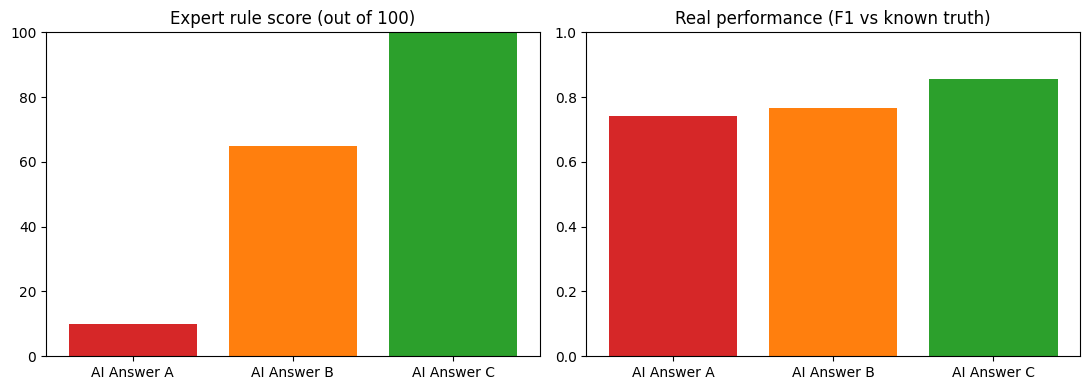


FINAL VERDICT
Best answer: AI Answer C
Lesson: a confident tone is not proof. The rule check and the real test agree on which answer is trustworthy.
Note: this simulated test uses a simple linear model. For real data, use DESeq2/edgeR/PyDESeq2 on raw counts.

Reproducibility log: numpy 2.1.3 | pandas 2.2.3 | seed = 42


In [ ]:

# Cell 5: Write the expert review in simple words and flag confident-but-wrong answers

def overconfident(claim):
    return re.search(r"100%|definitely|always|complete|perfect", claim, re.I) is not None

print("=" * 60)
print("EXPERT REVIEW REPORT")
print("=" * 60)

for name, r in review.items():
    claim = answers[name]["claim"]
    flag = overconfident(claim) and (r["rule_score"] < 70 or r["f1"] < 0.6)
    print(f"\n{name}")
    print(f"  Rule score: {r['rule_score']}/100 | Precision: {r['precision']} | Recall: {r['recall']} | F1: {r['f1']}")
    print(f"  Genes called: {r['genes_called']} (true: {r['true_hits']}, false: {r['false_hits']})")
    print(f"  AI claim: \"{claim}\"")
    if flag:
        print("  WARNING: CONFIDENT BUT WRONG. The claim is strong, but the method has real problems.")
    if r["failed"]:
        print("  Problems found:")
        for f in r["failed"]:
            print(f"   - {f['name']}")
            print(f"     Why it matters: {f['why']}")
            print(f"     Fix: {f['fix']}")
    else:
        print("  No rule problems found.")

# Chart: rule score vs real performance
names = list(review.keys())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(names, [review[n]["rule_score"] for n in names], color=["tab:red", "tab:orange", "tab:green"])
ax[0].set_title("Expert rule score (out of 100)"); ax[0].set_ylim(0, 100)
ax[1].bar(names, [review[n]["f1"] for n in names], color=["tab:red", "tab:orange", "tab:green"])
ax[1].set_title("Real performance (F1 vs known truth)"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

best = max(review, key=lambda n: review[n]["f1"])
print("\nFINAL VERDICT")
print(f"Best answer: {best}")
print("Lesson: a confident tone is not proof. The rule check and the real test agree on which answer is trustworthy.")
print("Note: this simulated test uses a simple linear model. For real data, use DESeq2/edgeR/PyDESeq2 on raw counts.")
print("\nReproducibility log: numpy", np.__version__, "| pandas", pd.__version__, "| seed = 42")